# Stage 04 — Scaling

## Objective

Compare Min-Max, Z-score, Robust and Quantile uniform/normal scaling on the same complete
69-feature training frame. The original-unit matrix is a reference, not a sixth fitted scaler.
Both quantile outputs are retained; the rubric permits either.

## Methodology

Reproduce the same train-only kNN10 completion, preserve every observed cell and its missingness
provenance, and retain all 8,173 rows. Fit each scaler on this complete original-unit training
matrix. No validation/reserved values or outcome labels choose scalers.

Use MinMax [0,1] with clip=False; StandardScaler ddof=0; RobustScaler median/IQR, unit_variance=False;
QuantileTransformer with 1,000 quantiles, subsample=None and seed=42 for both outputs.

$$
x'_{ij}=\frac{x_{ij}-\min_{train,j}}{\max_{train,j}-\min_{train,j}}.
$$

$$
z_{ij}=\frac{x_{ij}-\mu_{train,j}}{\sigma_{train,j}},\qquad
\sigma^2_{train,j}=\frac1{n}\sum_i(x_{ij}-\mu_{train,j})^2.
$$

$$
x'_{ij}=\frac{x_{ij}-\operatorname{median}_{train,j}}{Q_{.75,train,j}-Q_{.25,train,j}}.
$$

$$
u_{ij}=\widehat F_{train,j}(x_{ij}),\qquad
z_{ij}=\Phi^{-1}(\widehat F_{train,j}(x_{ij})).
$$

$$
Z_{gi}=|x_{gi}-\operatorname{median}_g(x)|,\qquad
W=\frac{N-G}{G-1}\frac{\sum_g n_g(\bar Z_g-\bar Z)^2}{\sum_g\sum_i(Z_{gi}-\bar Z_g)^2}.
$$

The optional median-centered Levene diagnostic compares observed BMI across the fixed training-age
median (59); identical groups enter every representation. ZIP dependence, ties and fitted transforms
limit p-value calibration. Shared nonzero affine scaling leaves W/p invariant. A small/non-small p
is not a scaler ranking or evidence about regression-residual homoscedasticity.

## Implementation

The shared module reconstructs the verified input only; this notebook independently fits
all five scalers. Code below retains the exact settings. Intermediate six-feature summaries,
parameter audits and correctness fixtures are folded; the consolidated results are primary.

In [1]:
from pathlib import Path
import hashlib
import os
import re
import subprocess
import sys
from time import perf_counter
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'myst.yml').is_file() and (p / 'src/validate_dataset.py').is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / '.venv':
    raise RuntimeError('Start in the repository and use the hcmus-wids .venv kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.tabular_data import (load_data, split_data, numerical_columns, numeric_audit,
    categorical_audit, prepare_numeric_training, memory_gib, CLINICAL_FIELDS,
    CATEGORICAL_FEATURES, REPRESENTATIVE_FEATURES, MISSING_TOKEN, LR_SETTINGS, KNN_MEMORY_MIB)

DATA_PATH = ROOT / 'data/raw/training.csv'
ID, TARGET, ZIP = 'patient_id', 'DiagPeriodL90D', 'patient_zip3'
df, raw_sha_before = load_data(ROOT)
train_index, validation_index, reserved_index = split_data(df)
clinical_fields = CLINICAL_FIELDS.copy()
FEATURES = REPRESENTATIVE_FEATURES.copy()
forbidden = clinical_fields | {ID, TARGET, ZIP, *CATEGORICAL_FEATURES, 'patient_gender'}
numerical_candidates = numerical_columns(df)
numerical_eligibility, bounded_share_features = numeric_audit(df, train_index, validation_index)
EXPANDED_FEATURES = numerical_candidates.copy()
air_features = {'Ozone', 'PM25', 'N02'}
frame_hash_before = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest()
dtypes_before, shape_before, columns_before = df.dtypes.copy(), df.shape, df.columns.copy()
outlier_holdout_hashes = {name:hashlib.sha256(pd.util.hash_pandas_object(df.loc[index],index=True).to_numpy().tobytes()).hexdigest()
    for name,index in {'Validation':validation_index,'Reserved':reserved_index}.items()}
stage03_adopted_training_rows = train_index.copy()  # Preserved keep-all decision before this stage's intervention.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':140})

preparation_start = perf_counter()
(outlier_train_original, outlier_original_missing, expanded_scaler, shared_knn,
 expanded_train_z, outlier_common_train_raw, outlier_common_train_z) = prepare_numeric_training(df, train_index, numerical_candidates)
outlier_features = numerical_candidates.copy()
outlier_common_imputed_mask = outlier_original_missing.copy(deep=True)
outlier_preparation_seconds = perf_counter()-preparation_start

outlier_features = list(numerical_candidates)
assert outlier_features == EXPANDED_FEATURES and len(outlier_features) == 69
assert set(outlier_features).isdisjoint(forbidden)
outlier_train_original = df.loc[train_index, outlier_features].copy(deep=True)
outlier_original_missing = outlier_train_original.isna()
outlier_train_hash = hashlib.sha256(pd.util.hash_pandas_object(outlier_train_original, index=True).to_numpy().tobytes()).hexdigest()
outlier_holdout_hashes = {name: hashlib.sha256(pd.util.hash_pandas_object(df.loc[index], index=True).to_numpy().tobytes()).hexdigest()
    for name, index in {"Validation": validation_index, "Reserved": reserved_index}.items()}
assert np.isfinite(outlier_train_original.to_numpy()[~outlier_original_missing.to_numpy()]).all()
assert train_index.intersection(validation_index).empty and train_index.intersection(reserved_index).empty

outlier_quartiles = outlier_train_original.quantile([.25, .75], interpolation="linear").T
outlier_audit_iqr = outlier_quartiles[.75] - outlier_quartiles[.25]
outlier_audit_sd = outlier_train_original.std(ddof=0)
outlier_feature_audit = pd.DataFrame({
    "Storage dtype": outlier_train_original.dtypes.astype(str),
    "Semantic role": numerical_eligibility["Semantic role"],
    "Observed training N": outlier_train_original.count(),
    "Natural missing N": outlier_original_missing.sum(),
    "Natural missing % (train)": outlier_original_missing.mean()*100,
    "Distinct observed N": outlier_train_original.nunique(),
    "Constant observed": outlier_train_original.nunique().eq(1),
    "Zero IQR": outlier_audit_iqr.eq(0), "Zero SD": outlier_audit_sd.eq(0),
    "Skewness (observed train)": outlier_train_original.skew(),
    "Semantic / timing note": numerical_eligibility["Reason"]})
outlier_feature_audit["High |skew| > 1 (descriptive)"] = outlier_feature_audit["Skewness (observed train)"].abs().gt(1)
outlier_feature_audit["IQR eligible"] = outlier_train_original.count().ge(4) & outlier_audit_iqr.gt(0) & np.isfinite(outlier_audit_iqr)
outlier_feature_audit["Z-score eligible"] = outlier_train_original.count().ge(2) & outlier_audit_sd.gt(0) & np.isfinite(outlier_audit_sd)
outlier_feature_audit["Redundancy review"] = "Retained; no correlation-based exclusion"
for columns, note in [
    (["male", "female"], "Complementary area shares; potentially repeated triggers"),
    (["education_bachelors", "education_graduate", "education_college_or_above"], "Overlapping education summaries retained"),
    (["income_household_100_to_150", "income_household_150_over", "income_household_six_figure"], "Overlapping income shares retained")]:
    outlier_feature_audit.loc[columns, "Redundancy review"] = note
outlier_feature_audit.index = outlier_feature_audit.index.copy().rename("Feature")
display(HTML('<details><summary>Outlier eligibility audit — all 69 numerical candidates</summary>'
    '<div style="overflow:auto;max-height:32rem">'+outlier_feature_audit.to_html(float_format="{:.4f}".format)+'</div></details>'))


stage03_retention_policy = {'Automatic deletion':False}

,Storage dtype,Semantic role,Observed training N,Natural missing N,Natural missing % (train),Distinct observed N,Constant observed,Zero IQR,Zero SD,Skewness (observed train),Semantic / timing note,High |skew| > 1 (descriptive),IQR eligible,Z-score eligible,Redundancy review
Feature,,,,,,,,,,,,,,,
patient_age,int64,Individual age,8173,0,0.0000,67,False,False,False,0.1204,Index/baseline alignment unverified,False,True,True,Retained; no correlation-based exclusion
bmi,float64,Individual BMI,2531,5642,69.0322,1037,False,False,False,0.9304,Post-metastatic; retrospective only,False,True,True,Retained; no correlation-based exclusion
population,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,0.4145,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
density,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,3.7989,Context/reference period unresolved; units vary,True,True,True,Retained; no correlation-based exclusion
age_median,float64,Area numerical summary,8173,0,0.0000,439,False,False,False,0.2867,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
age_under_10,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,0.0294,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_10_to_19,float64,"Area share [0,100]",8173,0,0.0000,440,False,False,False,0.9516,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_20s,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,1.7244,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion
age_30s,float64,"Area share [0,100]",8173,0,0.0000,438,False,False,False,1.1267,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion


### Common scaling input

In [2]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, QuantileTransformer
from scipy.stats import levene

SCALING_ORDER = ["Min-Max", "Standard", "Robust", "Quantile Uniform", "Quantile Normal"]
SCALING_VIOLIN_FEATURES = ["patient_age", "bmi", "density", "income_household_median",
                           "education_college_or_above", "PM25"]
SCALING_SEED = 42
scaling_train = outlier_common_train_raw.copy(deep=True)
assert scaling_train.index.equals(train_index) and list(scaling_train.columns) == outlier_features
assert scaling_train.index.is_unique and scaling_train.columns.is_unique
assert scaling_train.shape == (len(train_index), len(outlier_features)) and len(outlier_features) == 69
assert set(scaling_train.columns).isdisjoint(forbidden) and np.isfinite(scaling_train.to_numpy()).all()
assert stage03_adopted_training_rows.equals(train_index) and not stage03_retention_policy["Automatic deletion"]
pd.testing.assert_frame_equal(outlier_common_imputed_mask, outlier_original_missing)
pd.testing.assert_frame_equal(scaling_train.where(~outlier_common_imputed_mask), outlier_train_original)
assert train_index.intersection(validation_index).empty and train_index.intersection(reserved_index).empty
scaling_input_hash = hashlib.sha256(pd.util.hash_pandas_object(scaling_train, index=True).to_numpy().tobytes()).hexdigest()

scaling_audit = pd.DataFrame({
    "Semantic role": outlier_feature_audit["Semantic role"],
    "Original observed N": outlier_train_original.count(),
    "Imputed N": outlier_common_imputed_mask.sum(),
    "Completed distinct N": scaling_train.nunique(),
    "Constant completed": scaling_train.nunique().eq(1),
    "Largest identical-value share": scaling_train.apply(lambda column: column.value_counts(normalize=True).iloc[0]),
    "Skew observed": outlier_train_original.skew(), "Skew completed": scaling_train.skew(),
    "Bounded area share": scaling_train.columns.isin(bounded_share_features),
    "Finite completed": np.isfinite(scaling_train.to_numpy()).all(axis=0)}).rename_axis("Feature")
scaling_audit["Near-constant >=99%"] = scaling_audit["Largest identical-value share"].ge(.99)
scaling_audit["High |skew| >1 completed"] = scaling_audit["Skew completed"].abs().gt(1)
assert outlier_train_original.patient_age.notna().all()
SCALING_AGE_CUT = float(outlier_train_original.patient_age.median())
scaling_age_lower = outlier_train_original.patient_age.le(SCALING_AGE_CUT)
SCALING_LEVENE_FEATURE = "bmi"
SCALING_MIN_GROUP_N = 20  # Declared feasibility minimum, not a power guarantee.
SCALING_N_QUANTILES = min(1000, len(scaling_train))
scaling_models, scaling_frames, scaling_summaries = {}, {"Original": scaling_train.copy(deep=True)}, {}
scaling_runtime = {}

def describe_scaling(frame):
    """One row per feature; SD uses ddof=0 and pandas skew is undefined for constants."""
    q = frame.quantile([.01, .25, .5, .75, .99], interpolation="linear")
    return pd.DataFrame({"N": frame.count(), "Mean": frame.mean(), "Median": q.loc[.5],
        "SD (ddof 0)": frame.std(ddof=0), "Min": frame.min(), "Max": frame.max(),
        "Q1": q.loc[.25], "Q3": q.loc[.75], "IQR": q.loc[.75]-q.loc[.25],
        "P01": q.loc[.01], "P99": q.loc[.99],
        "Skewness": frame.skew().where(frame.nunique().gt(1)),
        "Finite": np.isfinite(frame.to_numpy()).all(axis=0)})

scaling_summaries["Original"] = describe_scaling(scaling_train)
display(pd.Series({"Training N": len(train_index), "Validation N (not fitted)": len(validation_index),
    "Reserved N (not fitted)": len(reserved_index), "Numerical features": scaling_train.shape[1],
    "Original missing / imputed cells": int(outlier_common_imputed_mask.to_numpy().sum()),
    "Constant features": int(scaling_audit["Constant completed"].sum()),
    "Near-constant features >=99%": int(scaling_audit["Near-constant >=99%"].sum()),
    "High |skew| >1 completed features": int(scaling_audit["High |skew| >1 completed"].sum()),
    "Age cut for later BMI diagnostic": SCALING_AGE_CUT}).to_frame("Scaling protocol"))
display(HTML('<details><summary>Scaling input audit — all 69 features and imputation provenance</summary>'
    '<div style="overflow:auto;max-height:32rem">'+scaling_audit.to_html(float_format="{:.6g}".format)+'</div></details>'))

,Scaling protocol
Training N,8173.0
Validation N (not fitted),2081.0
Reserved N (not fitted),2652.0
Numerical features,69.0
Original missing / imputed cells,5717.0
Constant features,0.0
Near-constant features >=99%,0.0
High |skew| >1 completed features,29.0
Age cut for later BMI diagnostic,59.0


,Semantic role,Original observed N,Imputed N,Completed distinct N,Constant completed,Largest identical-value share,Skew observed,Skew completed,Bounded area share,Finite completed,Near-constant >=99%,High |skew| >1 completed
Feature,,,,,,,,,,,,
patient_age,Individual age,8173,0,67,False,0.0382968,0.12041,0.12041,False,True,False,False
bmi,Individual BMI,2531,5642,2671,False,0.00880949,0.930413,1.14318,False,True,False,True
population,Area numerical summary,8173,0,443,False,0.0292426,0.414537,0.414537,False,True,False,False
density,Area numerical summary,8173,0,443,False,0.0292426,3.79886,3.79886,False,True,False,True
age_median,Area numerical summary,8173,0,439,False,0.0300991,0.286727,0.286727,False,True,False,False
age_under_10,"Area share [0,100]",8173,0,435,False,0.0292426,0.0293748,0.0293748,True,True,False,False
age_10_to_19,"Area share [0,100]",8173,0,440,False,0.0292426,0.95162,0.95162,True,True,False,False
age_20s,"Area share [0,100]",8173,0,435,False,0.0292426,1.7244,1.7244,True,True,False,True
age_30s,"Area share [0,100]",8173,0,438,False,0.0292426,1.12673,1.12673,True,True,False,True


### Min-Max

In [3]:
scaling_models["Min-Max"] = MinMaxScaler(feature_range=(0, 1), clip=False, copy=True)
start = perf_counter()
scaling_frames["Min-Max"] = pd.DataFrame(scaling_models["Min-Max"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Min-Max"] = perf_counter()-start
scaling_summaries["Min-Max"] = describe_scaling(scaling_frames["Min-Max"])
display(scaling_summaries["Min-Max"].loc[SCALING_VIOLIN_FEATURES,
    ["Min", "Max", "Median", "IQR", "Skewness"]].round(6))
print("Training endpoints, observed across all features:",
      scaling_frames["Min-Max"].min().min(), scaling_frames["Min-Max"].max().max())

,Min,Max,Median,IQR,Skewness
patient_age,0.0,1.0,0.561644,0.232877,0.120410
bmi,0.0,1.0,0.210141,0.049563,1.143179
density,0.0,1.0,0.034523,0.070860,3.798859
income_household_median,0.0,1.0,0.339741,0.196008,0.839379
education_college_or_above,0.0,1.0,0.332856,0.212600,0.642871
PM25,0.0,1.0,0.589623,0.206025,-0.352618


Training endpoints, observed across all features: 0.0 1.0000000000000002


### Standard

In [4]:
scaling_models["Standard"] = StandardScaler(with_mean=True, with_std=True, copy=True)
start = perf_counter()
scaling_frames["Standard"] = pd.DataFrame(scaling_models["Standard"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Standard"] = perf_counter()-start
scaling_summaries["Standard"] = describe_scaling(scaling_frames["Standard"])
display(scaling_summaries["Standard"].loc[SCALING_VIOLIN_FEATURES,
    ["Mean", "SD (ddof 0)", "Min", "Max", "Skewness"]].round(6))
print("Maximum absolute transformed mean:", scaling_frames["Standard"].mean().abs().max())
print("Maximum |SD-1| among nonconstant features:",
      (scaling_frames["Standard"].std(ddof=0)[scaling_train.nunique().gt(1)]-1).abs().max())

,Mean,SD (ddof 0),Min,Max,Skewness
patient_age,0.0,1.0,-3.099862,2.405899,0.120410
bmi,0.0,1.0,-4.163001,15.548476,1.143179
density,0.0,1.0,-0.704905,10.472376,3.798859
income_household_median,-0.0,1.0,-2.265523,3.895343,0.839379
education_college_or_above,-0.0,1.0,-2.268982,4.217572,0.642871
PM25,0.0,1.0,-3.159124,2.374735,-0.352618


Maximum absolute transformed mean: 1.818739022647901e-15
Maximum |SD-1| among nonconstant features: 2.220446049250313e-16


### Robust

In [5]:
scaling_models["Robust"] = RobustScaler(with_centering=True, with_scaling=True,
    quantile_range=(25, 75), unit_variance=False, copy=True)
start = perf_counter()
scaling_frames["Robust"] = pd.DataFrame(scaling_models["Robust"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Robust"] = perf_counter()-start
scaling_summaries["Robust"] = describe_scaling(scaling_frames["Robust"])
display(scaling_summaries["Robust"].loc[SCALING_VIOLIN_FEATURES,
    ["Median", "IQR", "SD (ddof 0)", "Min", "Max", "Skewness"]].round(6))
print("Maximum |median|:", scaling_frames["Robust"].median().abs().max())
print("Maximum |IQR-1| among positive-IQR features:",
      (scaling_summaries["Robust"].IQR[scaling_summaries["Original"].IQR.gt(0)]-1).abs().max())

,Median,IQR,SD (ddof 0),Min,Max,Skewness
patient_age,0.0,1.0,0.779932,-2.411765,1.882353,0.120410
bmi,0.0,1.0,1.023576,-4.239841,15.936346,1.143179
density,0.0,1.0,1.262597,-0.487208,13.625191,3.798859
income_household_median,0.0,1.0,0.828104,-1.733302,3.368536,0.839379
education_college_or_above,0.0,1.0,0.725140,-1.565644,3.138020,0.642871
PM25,0.0,1.0,0.877107,-2.861904,1.991879,-0.352618


Maximum |median|: 0.0
Maximum |IQR-1| among positive-IQR features: 0.0


### Quantile transforms

In [6]:
for name, distribution in [("Quantile Uniform", "uniform"), ("Quantile Normal", "normal")]:
    model = QuantileTransformer(n_quantiles=SCALING_N_QUANTILES,
        output_distribution=distribution, subsample=None, random_state=SCALING_SEED, copy=True)
    start = perf_counter()
    values = model.fit_transform(scaling_train)
    scaling_runtime[name] = perf_counter()-start
    scaling_models[name] = model
    scaling_frames[name] = pd.DataFrame(values, index=train_index, columns=outlier_features)
    scaling_summaries[name] = describe_scaling(scaling_frames[name])
    assert model.n_quantiles_ == SCALING_N_QUANTILES and np.isfinite(values).all()
scaling_quantile_examples = pd.concat({name: scaling_summaries[name].loc[SCALING_VIOLIN_FEATURES,
    ["Mean", "Median", "SD (ddof 0)", "Min", "Max", "IQR", "Skewness"]]
    for name in ["Quantile Uniform", "Quantile Normal"]}, names=["Transformation", "Feature"])
display(HTML('<div style="overflow:auto">'+scaling_quantile_examples.to_html(float_format="{:.6f}".format)+'</div>'))
print("Same fitted CDF knots across uniform/normal:", np.array_equal(
    scaling_models["Quantile Uniform"].quantiles_, scaling_models["Quantile Normal"].quantiles_))

Same fitted CDF knots across uniform/normal: True


## Results

The full 414-row reference/transformation table and fitted parameters are expandable.
Three violin figures cover the same six declared features, showing observed/imputed groups
with separate numerical axes and printed counts. KDE widths are not sample sizes; equal/tied
values and endpoint masses limit the requested quantile shapes.

### Consolidated comparison

In [7]:
scaling_full_summary = pd.concat(scaling_summaries, names=["Transformation", "Feature"])
scaling_fitted_parameters = pd.DataFrame({
    "Train min": scaling_models["Min-Max"].data_min_, "Train max": scaling_models["Min-Max"].data_max_,
    "MinMax data range": scaling_models["Min-Max"].data_range_, "MinMax multiplier": scaling_models["Min-Max"].scale_,
    "MinMax offset": scaling_models["Min-Max"].min_, "Train mean": scaling_models["Standard"].mean_,
    "Train variance ddof0": scaling_models["Standard"].var_, "Standard scale": scaling_models["Standard"].scale_,
    "Train median": scaling_models["Robust"].center_, "Robust IQR scale": scaling_models["Robust"].scale_,
    "Quantile knots N": SCALING_N_QUANTILES,
    "Distinct quantile knots N": [len(np.unique(column)) for column in scaling_models["Quantile Uniform"].quantiles_.T],
    "Uniform lower-bound N": scaling_frames["Quantile Uniform"].eq(0).sum(),
    "Uniform upper-bound N": scaling_frames["Quantile Uniform"].eq(1).sum()},
    index=pd.Index(outlier_features, name="Feature"))
scaling_overview = pd.DataFrame([{
    "Transformation": name, "Training N": len(train_index), "Features": len(outlier_features),
    "Min feature SD": summary["SD (ddof 0)"].min(), "Max feature SD": summary["SD (ddof 0)"].max(),
    "Median absolute feature skew": summary.Skewness.abs().median(),
    "High |skew|>1 features": int(summary.Skewness.abs().gt(1).sum()),
    "Finite features": int(summary.Finite.sum()), "Fit + transform (s)": scaling_runtime.get(name, np.nan)}
    for name, summary in scaling_summaries.items()]).set_index("Transformation")
display(HTML('<div style="overflow:auto">'+scaling_overview.to_html(float_format="{:.6g}".format, na_rep="reference")+'</div>'))
for title, table in [("Scaling fitted parameters — all 69 features", scaling_fitted_parameters),
                     ("All 414 feature/representation summaries — original plus five scalers", scaling_full_summary)]:
    display(HTML('<details><summary>'+title+'</summary><div style="overflow:auto;max-height:32rem">'
        +table.to_html(float_format="{:.9g}".format)+'</div></details>'))
scaling_property_errors = pd.Series({
    "MinMax max |minimum-0| (nonconstant)": scaling_frames["Min-Max"].min()[scaling_train.nunique().gt(1)].abs().max(),
    "MinMax max |maximum-1| (nonconstant)": (scaling_frames["Min-Max"].max()[scaling_train.nunique().gt(1)]-1).abs().max(),
    "Standard max |mean|": scaling_frames["Standard"].mean().abs().max(),
    "Standard max |SD-1| (nonconstant)": (scaling_frames["Standard"].std(ddof=0)[scaling_train.nunique().gt(1)]-1).abs().max(),
    "Robust max |median|": scaling_frames["Robust"].median().abs().max(),
    "Robust max |IQR-1| (positive IQR)": (scaling_summaries["Robust"].IQR[scaling_summaries["Original"].IQR.gt(0)]-1).abs().max(),
    "Maximum affine skewness change": max((scaling_summaries[name].Skewness-scaling_summaries["Original"].Skewness).abs().max()
                                          for name in ["Min-Max", "Standard", "Robust"])})
display(scaling_property_errors.to_frame("Mechanical check error (not a ranking)"))

,Training N,Features,Min feature SD,Max feature SD,Median absolute feature skew,High |skew|>1 features,Finite features,Fit + transform (s)
Transformation,,,,,,,,
Original,8173,69,0.234718,238316,0.859075,29,69,reference
Min-Max,8173,69,0.0418242,0.233574,0.859075,29,69,0.00441221
Standard,8173,69,1,1,0.859075,29,69,0.00611208
Robust,8173,69,0.596002,4.44572,0.859075,29,69,0.0242367
Quantile Uniform,8173,69,0.288657,0.293802,0.000180645,0,69,0.122699
Quantile Normal,8173,69,1.00024,1.66968,0.0849589,2,69,0.142676


,Train min,Train max,MinMax data range,MinMax multiplier,MinMax offset,Train mean,Train variance ddof0,Standard scale,Train median,Robust IQR scale,Quantile knots N,Distinct quantile knots N,Uniform lower-bound N,Uniform upper-bound N
Feature,,,,,,,,,,,,,,
patient_age,18,91,73,0.0136986301,-0.246575342,59.1005751,175.79681,13.2588389,59,17,1000,73,6,134
bmi,14,85,71,0.014084507,-0.197183099,28.9949746,12.9741326,3.60196232,28.92,3.519,1000,858,1,1
population,635.545455,53351.2222,52715.6768,1.89696891e-05,-0.0120560997,20607.5571,151609869,12312.9959,19717.8696,20499.9673,1000,369,3,33
density,0.916666667,21172,21171.0833,4.72342385e-05,-4.3298052e-05,1336.08969,3587680.93,1894.11745,731.814286,1500.17606,1000,365,2,14
age_median,30.8461539,54.57,23.7238461,0.0421516812,-1.30021724,40.4763893,15.1209775,3.88857011,40.55,5.37767857,1000,376,8,1
age_under_10,5.63793103,16.4818182,10.8438871,0.0922178539,-0.5199179,11.0550334,2.1544459,1.46780309,10.9442857,1.86222222,1000,373,6,24
age_10_to_19,6.31428571,27.5307692,21.2164835,0.0471331641,-0.297612265,12.9777746,3.69734994,1.92284943,13.0098039,2.24485126,1000,372,14,8
age_20s,5.925,36.9,30.975,0.0322841001,-0.191283293,13.3225484,10.7504151,3.27878256,12.615493,3.71748251,1000,363,2,11
age_30s,6.8137931,25.4714286,18.6576355,0.0535973597,-0.36520132,12.9691369,5.36946982,2.31721165,12.4426471,2.75647163,1000,366,6,14


,Mechanical check error (not a ranking)
MinMax max |minimum-0| (nonconstant),0.000000e+00
MinMax max |maximum-1| (nonconstant),2.220446e-16
Standard max |mean|,1.818739e-15
Standard max |SD-1| (nonconstant),2.220446e-16
Robust max |median|,0.000000e+00
Robust max |IQR-1| (positive IQR),0.000000e+00
Maximum affine skewness change,2.415845e-13


### Observed-BMI variance diagnostic

In [8]:
def scaling_levene_diagnostic(first, second, min_group_n=SCALING_MIN_GROUP_N):
    """Two fixed groups; missing values dropped, invalid/degenerate support made explicit."""
    groups = [pd.Series(values).dropna().to_numpy(dtype=float) for values in [first, second]]
    result = {"Lower-age observed N": len(groups[0]), "Upper-age observed N": len(groups[1]),
        "Lower-age sample variance": np.nan, "Upper-age sample variance": np.nan,
        "Levene W": np.nan, "Nominal p (ZIP dependence)": np.nan, "Status": "NOT EVALUATED"}
    if any(len(values) < min_group_n for values in groups):
        result["Status"] = "NOT EVALUATED: insufficient group support"
        return result
    if any(not np.isfinite(values).all() for values in groups):
        result["Status"] = "NOT EVALUATED: nonfinite group"
        return result
    if any(np.unique(values).size < 2 for values in groups):
        result["Status"] = "NOT EVALUATED: constant group"
        return result
    deviations = [np.abs(values-np.median(values)) for values in groups]
    denominator = sum(np.square(values-values.mean()).sum() for values in deviations)
    if denominator <= 0:
        result["Status"] = "NOT EVALUATED: constant centered deviations"
        return result
    test = levene(*groups, center="median", nan_policy="raise")
    result.update({"Lower-age sample variance": np.var(groups[0], ddof=1),
        "Upper-age sample variance": np.var(groups[1], ddof=1), "Levene W": float(test.statistic),
        "Nominal p (ZIP dependence)": float(test.pvalue),
        "Status": "COMPUTED: nominal only; independence not established"})
    return result

scaling_bmi_observed = ~outlier_common_imputed_mask[SCALING_LEVENE_FEATURE]
scaling_levene = pd.DataFrame({name: scaling_levene_diagnostic(
    frame.loc[scaling_bmi_observed & scaling_age_lower, SCALING_LEVENE_FEATURE],
    frame.loc[scaling_bmi_observed & ~scaling_age_lower, SCALING_LEVENE_FEATURE])
    for name, frame in scaling_frames.items()}).T.rename_axis("Transformation")
print(f"Fixed age groups: age <= {SCALING_AGE_CUT:g} vs age > {SCALING_AGE_CUT:g}; observed BMI only.")
display(HTML('<div style="overflow:auto">'+scaling_levene.to_html(float_format="{:.6g}".format,
    formatters={"Status": lambda value: "COMPUTED: nominal" if value.startswith("COMPUTED") else value})+'</div>'))
if scaling_levene["Levene W"].notna().all():
    display(HTML(f"<p>Observed W: original={scaling_levene.loc['Original','Levene W']:.6g}, "
        f"uniform={scaling_levene.loc['Quantile Uniform','Levene W']:.6g}, "
        f"normal={scaling_levene.loc['Quantile Normal','Levene W']:.6g}. "
        "Affine rows should coincide; nonlinear differences describe fitted transformations, "
        "not a formally validated improvement or a scaler winner.</p>"))

Fixed age groups: age <= 59 vs age > 59; observed BMI only.


,Lower-age observed N,Upper-age observed N,Lower-age sample variance,Upper-age sample variance,Levene W,Nominal p (ZIP dependence),Status
Transformation,,,,,,,
Original,1323,1208,36.6656,30.2071,4.28563,0.038537,COMPUTED: nominal
Min-Max,1323,1208,0.00727348,0.00599228,4.28563,0.038537,COMPUTED: nominal
Standard,1323,1208,2.82606,2.32825,4.28563,0.038537,COMPUTED: nominal
Robust,1323,1208,2.96088,2.43933,4.28563,0.038537,COMPUTED: nominal
Quantile Uniform,1323,1208,0.146654,0.142596,3.82537,0.0505922,COMPUTED: nominal
Quantile Normal,1323,1208,2.23614,2.08421,3.87785,0.0490361,COMPUTED: nominal


### Provenance-aware violins

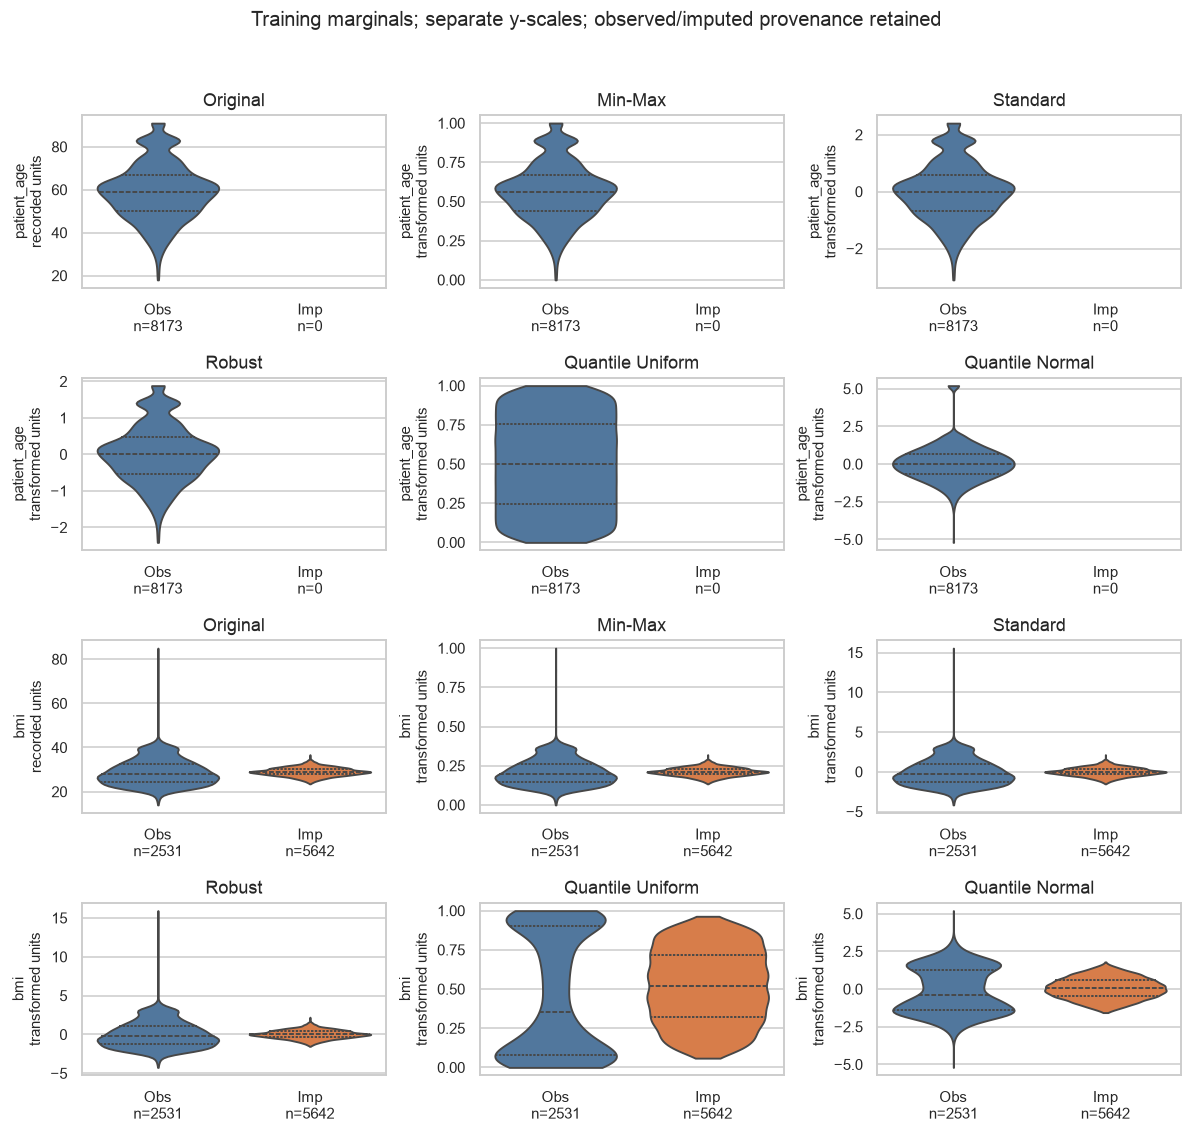

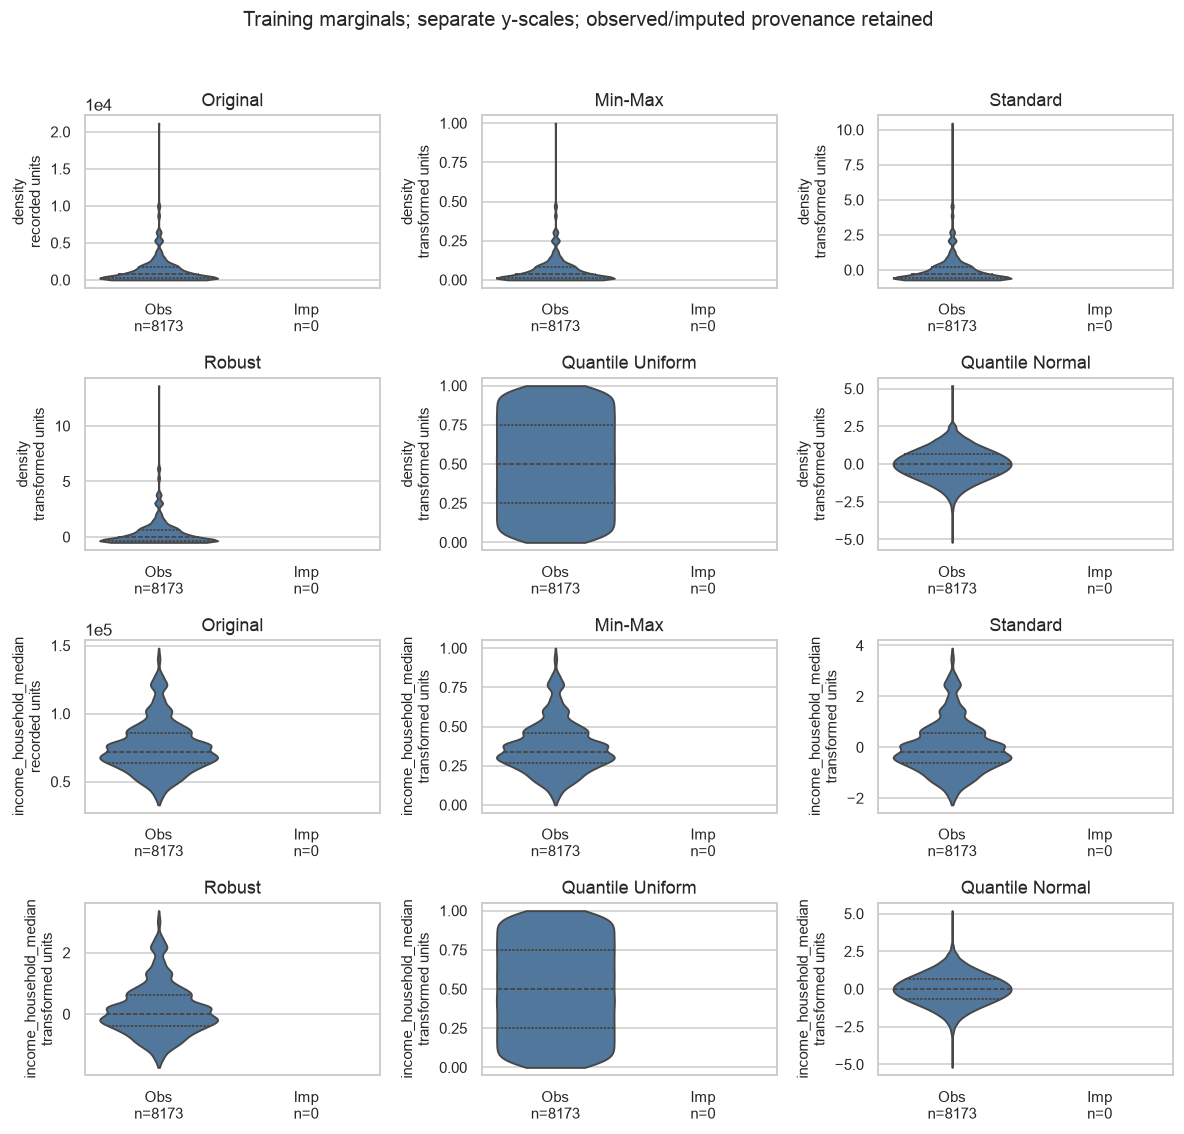

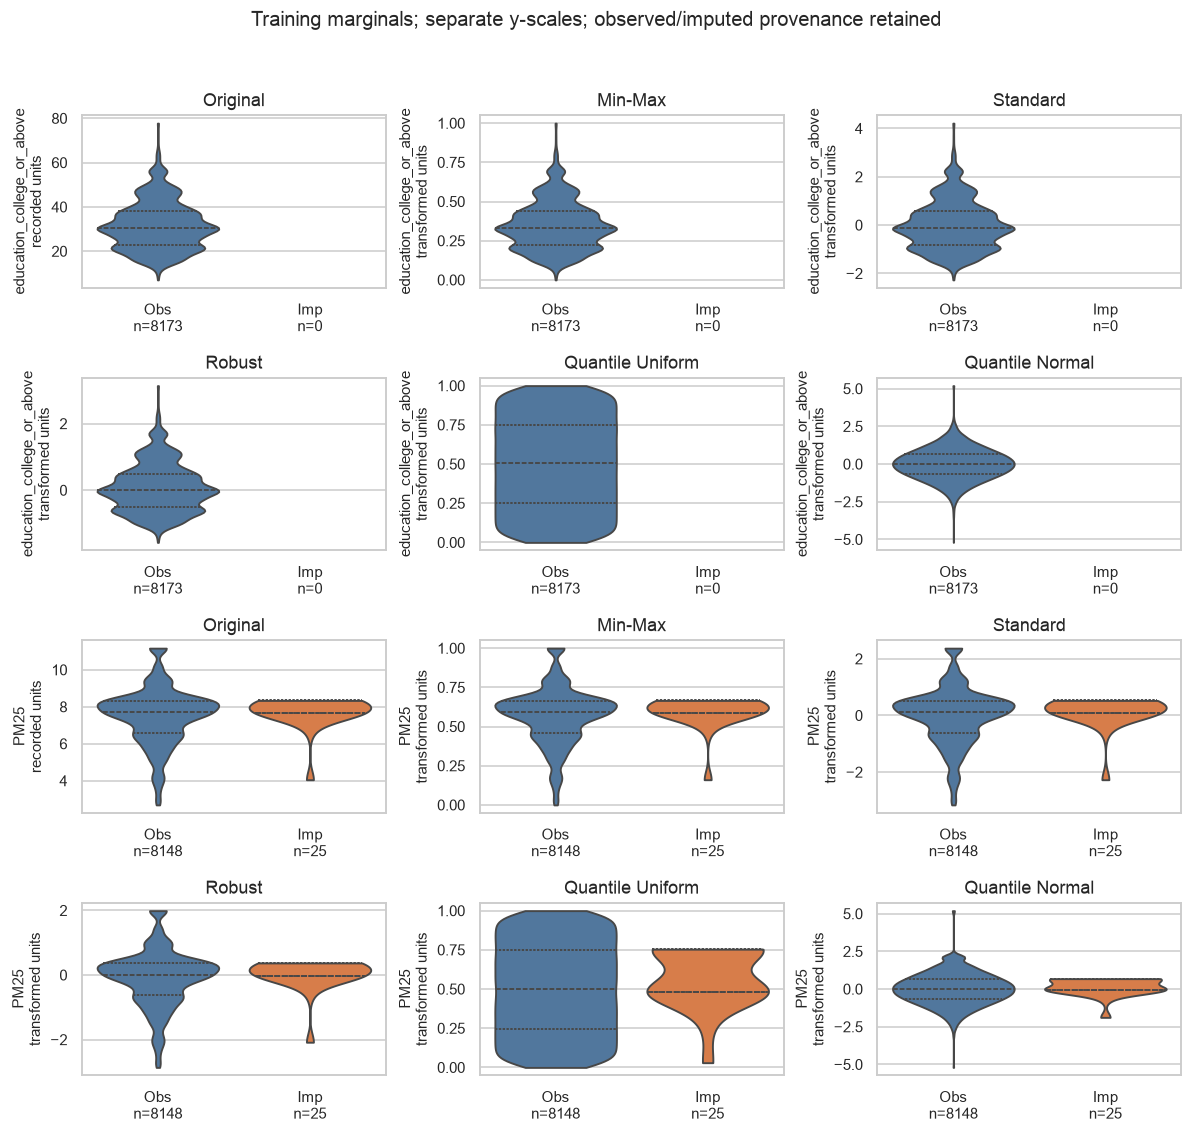

In [9]:
scaling_plot_order = ["Original", *SCALING_ORDER]
for first_feature in range(0, len(SCALING_VIOLIN_FEATURES), 2):
    features = SCALING_VIOLIN_FEATURES[first_feature:first_feature+2]
    fig, axes = plt.subplots(2*len(features), 3, figsize=(11, 10.5), squeeze=False)
    for row, feature in enumerate(features):
        provenance = np.where(outlier_common_imputed_mask[feature], "Imputed", "Observed")
        counts = pd.Series(provenance).value_counts()
        for column, name in enumerate(scaling_plot_order):
            ax = axes[2*row+column//3, column%3]
            plot_data = pd.DataFrame({"Value": scaling_frames[name][feature].to_numpy(), "Provenance": provenance})
            variable_groups = [group for group in ["Observed", "Imputed"]
                               if plot_data.loc[plot_data.Provenance.eq(group), "Value"].nunique() > 1]
            if variable_groups:
                sns.violinplot(data=plot_data[plot_data.Provenance.isin(variable_groups)],
                    x="Provenance", y="Value", hue="Provenance", order=["Observed", "Imputed"],
                    hue_order=["Observed", "Imputed"], palette={"Observed": "#4477AA", "Imputed": "#EE7733"},
                    inner="quart", cut=0, density_norm="width", common_norm=False, legend=False, ax=ax)
            for position, group in enumerate(["Observed", "Imputed"]):
                values = plot_data.loc[plot_data.Provenance.eq(group), "Value"]
                if len(values) and values.nunique() == 1:
                    ax.plot(position, values.iloc[0], marker="o", color="#4477AA" if group == "Observed" else "#EE7733")
            ax.set_xticks([0, 1], [f"Obs\nn={counts.get('Observed', 0)}", f"Imp\nn={counts.get('Imputed', 0)}"], fontsize=10)
            ax.set_title(name, fontsize=12)
            ax.set_xlabel("")
            ax.set_ylabel(f"{feature}\n"+("recorded units" if name == "Original" else "transformed units"), fontsize=10)
            ax.tick_params(axis="y", labelsize=10)
            ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 4))
    fig.suptitle("Training marginals; separate y-scales; observed/imputed provenance retained", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .96))
    plt.show()

## Discussion

Affine scalers change units/location/scale while retaining marginal shape: density skewness
remains 3.798859. Quantile remapping changes spacing and tails; normal output does not imply
joint Gaussianity. Its empirical SD can reach 1.669680 for `farmer`, where repeated endpoint
mass limits the target approximation. Observed BMI SD is about 5.798 versus 1.926 among imputed
cells; the narrower estimated distribution is not recovered missing-data truth.

Levene W=4.285635 for original and affine views, as expected; the quantile rows differ
nonlinearly. Their nominal p-values around .05 do not establish improved variance equality.
No predictive comparison is performed in this descriptive stage.

In [10]:
scaling_recommendation = {"Adopted sample policy": "Keep all original training rows; preserve anomaly flags",
    "Scaling winner": "None declared; conditional candidates require fold-local downstream evaluation",
    "Stage 05": "See the independent Stage 05 comparison", "Predictive pipeline": "Not yet validated"}
density_skews = {name: scaling_summaries[name].loc["density", "Skewness"] for name in scaling_plot_order}
bmi_observed_skew = scaling_audit.loc["bmi", "Skew observed"]
bmi_completed_skew = scaling_audit.loc["bmi", "Skew completed"]
scaling_max_normal_sd_feature = scaling_summaries["Quantile Normal"]["SD (ddof 0)"].idxmax()
scaling_max_normal_boundary_n = int(scaling_fitted_parameters.loc[scaling_max_normal_sd_feature,
    ["Uniform lower-bound N", "Uniform upper-bound N"]].sum())
scaling_bmi_original_sd = float(outlier_train_original.bmi.std(ddof=0))
scaling_bmi_imputed_sd = float(scaling_train.loc[outlier_common_imputed_mask.bmi, "bmi"].std(ddof=0))
display(HTML(pd.Series(scaling_recommendation).to_frame("Scaling conclusion").to_html()))
display(HTML(
    f"<p><strong>Computed evidence:</strong> all five methods cover {len(train_index):,} rows and {len(outlier_features)} features. "
    f"Density skewness: original={density_skews['Original']:.3f}, Min-Max={density_skews['Min-Max']:.3f}, "
    f"Standard={density_skews['Standard']:.3f}, Robust={density_skews['Robust']:.3f}, "
    f"uniform={density_skews['Quantile Uniform']:.3f}, normal={density_skews['Quantile Normal']:.3f}. "
    "Affine rescaling retains shape; quantile remapping changes its empirical shape without proving utility.</p>"
    f"<p>BMI has {int(scaling_audit.loc['bmi','Original observed N']):,} original observations and "
    f"{int(scaling_audit.loc['bmi','Imputed N']):,} imputed training cells. Observed-only skew={bmi_observed_skew:.3f}; "
    f"completed skew={bmi_completed_skew:.3f}. This documents a representation difference, not recovered missing-data truth. "
    f"For Quantile Normal, empirical feature SD ranges from {scaling_summaries['Quantile Normal']['SD (ddof 0)'].min():.4f} "
    f"to {scaling_summaries['Quantile Normal']['SD (ddof 0)'].max():.4f}; a requested normal target does not enforce exact empirical SD=1.</p>"
    f"<p>The largest Quantile Normal SD occurs for {scaling_max_normal_sd_feature}; "
    f"{scaling_max_normal_boundary_n:,}/{len(train_index):,} records map to its fitted endpoints. "
    "Repeated endpoint masses limit the target approximation and should not be called Gaussian merely because of the requested output. "
    f"BMI observed-only SD={scaling_bmi_original_sd:.3f}, versus SD={scaling_bmi_imputed_sd:.3f} among its imputed cells. "
    "The narrower estimated-value violin is not evidence that the naturally missing patients truly have lower variability; "
    "it also helps explain why separate provenance views matter after a pooled quantile transformation.</p>"))

,Scaling conclusion
Adopted sample policy,Keep all original training rows; preserve anomaly flags
Scaling winner,None declared; conditional candidates require fold-local downstream evaluation
Stage 05,See the independent Stage 05 comparison
Predictive pipeline,Not yet validated


## Conclusion

No global scaler winner is declared. Standard is a transparent scale-sensitive baseline;
Robust emphasizes central spread, Min-Max uses the fitted range, and quantiles require
accepting nonlinear geometry and tail saturation. Later prediction must refit scaling
inside training folds. Continue with [Stage 05](05_encoding.ipynb).

In [11]:
scaling_checks = {}
fixture = pd.DataFrame({"measurement": [0., 2., 4.], "constant": [7., 7., 7.]}, index=["a", "b", "c"])
fixture_before = fixture.copy(deep=True)
known_minmax = MinMaxScaler(clip=False).fit(fixture)
known_standard = StandardScaler().fit(fixture)
known_robust = RobustScaler().fit(fixture)
np.testing.assert_allclose(known_minmax.transform(fixture)[:, 0], [0, .5, 1])
np.testing.assert_allclose(known_standard.mean_, [2, 7])
np.testing.assert_allclose(known_standard.var_, [8/3, 0])
np.testing.assert_allclose(known_standard.transform(fixture)[:, 0], [-np.sqrt(1.5), 0, np.sqrt(1.5)])
np.testing.assert_allclose(known_robust.center_, [2, 7])
np.testing.assert_allclose(known_robust.scale_, [2, 1])
np.testing.assert_allclose(known_robust.transform(fixture)[:, 0], [-1, 0, 1])
for model in [known_minmax, known_standard, known_robust]:
    np.testing.assert_allclose(model.transform(fixture)[:, 1], 0)
unseen = pd.DataFrame({"measurement": [-2., 6.], "constant": [7., 7.]})
np.testing.assert_allclose(known_minmax.transform(unseen)[:, 0], [-.5, 1.5])
np.testing.assert_allclose(known_standard.transform(unseen)[:, 0], [-np.sqrt(6), np.sqrt(6)])
np.testing.assert_allclose(known_robust.transform(unseen)[:, 0], [-2, 2])
pd.testing.assert_frame_equal(fixture, fixture_before)
scaling_checks["Known affine formulas, constants and unbounded future inputs"] = True

scaling_fixture_quantiles = {}
for distribution in ["uniform", "normal"]:
    model = QuantileTransformer(n_quantiles=3, output_distribution=distribution, subsample=None, random_state=SCALING_SEED)
    transformed = model.fit_transform(fixture)
    assert model.output_distribution == distribution and np.isfinite(transformed).all()
    assert np.unique(transformed[:, 1]).size == 1  # Constant remains a mass point, not a target distribution.
    if distribution == "uniform": np.testing.assert_allclose(transformed[:, 0], [0, .5, 1])
    else:
        assert transformed[0, 0] < 0 < transformed[-1, 0]
        np.testing.assert_allclose(transformed[1, 0], 0, atol=1e-12)
    np.testing.assert_allclose(model.transform(unseen)[:, 0], transformed[[0, -1], 0])
    repeated = np.array([[0.], [1.], [1.], [2.]])
    repeated_before = repeated.copy()
    duplicate_model = QuantileTransformer(n_quantiles=4, output_distribution=distribution, subsample=None, random_state=SCALING_SEED)
    duplicate_result = duplicate_model.fit_transform(repeated)
    assert np.isfinite(duplicate_result).all() and duplicate_result[1, 0] == duplicate_result[2, 0]
    assert (np.diff(duplicate_result[:, 0]) >= 0).all()
    np.testing.assert_array_equal(repeated, repeated_before)
    scaling_fixture_quantiles[distribution] = transformed.tolist()
pd.testing.assert_frame_equal(fixture, fixture_before)
scaling_checks["Quantile modes, ties/constants, monotonicity, finite tail saturation and input preservation"] = True

known_levene = scaling_levene_diagnostic([0, 1, 2, 3], [0, 2, 4, 6], min_group_n=2)
np.testing.assert_allclose(known_levene["Levene W"], 2.4)
assert np.isnan(scaling_levene_diagnostic([1], [2])["Levene W"])
assert "constant group" in scaling_levene_diagnostic([1]*20, list(range(20)))["Status"]
assert "centered deviations" in scaling_levene_diagnostic([0, 1], [2, 3], min_group_n=2)["Status"]
scaling_checks["Known median-Levene W=2.4 and insufficient/constant/degenerate-group handling"] = True

assert list(scaling_models) == SCALING_ORDER and list(scaling_frames) == ["Original", *SCALING_ORDER]
assert len(scaling_full_summary) == 6*len(outlier_features)
for name, frame in scaling_frames.items():
    assert frame.index.equals(train_index) and frame.columns.equals(scaling_train.columns)
    assert frame.shape == scaling_train.shape and np.isfinite(frame.to_numpy()).all()
    assert scaling_summaries[name].N.eq(len(train_index)).all()
    # Sort each original feature; every transform must be nondecreasing (ties allowed).
    order = np.argsort(scaling_train.to_numpy(), axis=0, kind="stable")
    ordered = np.take_along_axis(frame.to_numpy(), order, axis=0)
    assert (np.diff(ordered, axis=0) >= -1e-10).all()
    if name != "Original":
        assert scaling_models[name].n_features_in_ == len(outlier_features)
        np.testing.assert_array_equal(scaling_models[name].feature_names_in_, outlier_features)
for name in ["Min-Max", "Quantile Uniform"]:
    assert scaling_frames[name].to_numpy().min() >= -1e-10 and scaling_frames[name].to_numpy().max() <= 1+1e-10
np.testing.assert_allclose(scaling_models["Min-Max"].data_min_, scaling_train.min(), rtol=0, atol=1e-10)
np.testing.assert_allclose(scaling_models["Min-Max"].data_max_, scaling_train.max(), rtol=0, atol=1e-10)
np.testing.assert_allclose(scaling_models["Standard"].mean_, scaling_train.mean(), rtol=1e-12, atol=1e-10)
np.testing.assert_allclose(scaling_models["Standard"].var_, scaling_train.var(ddof=0), rtol=1e-12, atol=1e-10)
assert scaling_models["Standard"].n_samples_seen_ == len(train_index)
assert scaling_models["Min-Max"].n_samples_seen_ == len(train_index)
np.testing.assert_allclose(scaling_models["Robust"].center_, scaling_train.median(), rtol=0, atol=1e-10)
positive_iqr = scaling_summaries["Original"].IQR.gt(10*np.finfo(float).eps)
np.testing.assert_allclose(scaling_models["Robust"].scale_[positive_iqr], scaling_summaries["Original"].IQR[positive_iqr], rtol=1e-12)
assert scaling_property_errors.dropna().lt(1e-9).all()
scaling_checks["Five complete aligned finite transformations, monotonicity, fitted train parameters and mechanical invariants"] = True

uniform_model = scaling_models["Quantile Uniform"]
normal_model = scaling_models["Quantile Normal"]
np.testing.assert_array_equal(uniform_model.quantiles_, normal_model.quantiles_)
np.testing.assert_array_equal(uniform_model.references_, np.linspace(0, 1, SCALING_N_QUANTILES))
np.testing.assert_allclose(uniform_model.quantiles_, np.percentile(scaling_train, uniform_model.references_*100, axis=0), rtol=1e-12, atol=1e-10)
for name in ["Quantile Uniform", "Quantile Normal"]:
    model = scaling_models[name]
    assert model.subsample is None and model.random_state == SCALING_SEED
    repeated_model = QuantileTransformer(**model.get_params())
    repeated_values = repeated_model.fit_transform(scaling_train)
    np.testing.assert_array_equal(repeated_values, scaling_frames[name].to_numpy())
del repeated_model, repeated_values
scaling_checks["Full-training fitted quantile grids and exact fixed-settings repeat for both outputs"] = True

for name in ["Min-Max", "Standard", "Robust"]:
    if pd.notna(scaling_levene.loc["Original", "Levene W"]):
        np.testing.assert_allclose(scaling_levene.loc[name, ["Levene W", "Nominal p (ZIP dependence)"]].to_numpy(dtype=float),
            scaling_levene.loc["Original", ["Levene W", "Nominal p (ZIP dependence)"]].to_numpy(dtype=float), rtol=1e-9, atol=1e-10)
assert int(scaling_bmi_observed.sum()) == int(outlier_train_original.bmi.count())
scaling_checks["Same observed-only BMI groups and affine Levene invariance"] = True

pd.testing.assert_frame_equal(scaling_train, outlier_common_train_raw)
assert hashlib.sha256(pd.util.hash_pandas_object(scaling_train, index=True).to_numpy().tobytes()).hexdigest() == scaling_input_hash
pd.testing.assert_frame_equal(outlier_common_imputed_mask, outlier_original_missing)
pd.testing.assert_frame_equal(scaling_train.where(~outlier_common_imputed_mask), outlier_train_original)
assert hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest() == frame_hash_before
for name, index in {"Validation": validation_index, "Reserved": reserved_index}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(df.loc[index], index=True).to_numpy().tobytes()).hexdigest() == outlier_holdout_hashes[name]
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before
assert df.shape == (12906, 83) and set(scaling_train.columns).isdisjoint(forbidden)
assert stage03_adopted_training_rows.equals(train_index)
scaling_checks["Raw/schema, complete train data, original observations/provenance and holdouts unchanged"] = True
display(pd.Series(scaling_checks, name="PASS").to_frame())
print(f"Stage 04 complete: {len(scaling_models)} scaling configurations; {len(scaling_train)} x {len(outlier_features)} common input; {len(scaling_full_summary)} feature/representation summaries.")
print("No global predictive winner. Stage 05 Categorical Encoding can proceed as a separate controlled experiment.")

,PASS
"Known affine formulas, constants and unbounded future inputs",True
"Quantile modes, ties/constants, monotonicity, finite tail saturation and input preservation",True
Known median-Levene W=2.4 and insufficient/constant/degenerate-group handling,True
"Five complete aligned finite transformations, monotonicity, fitted train parameters and mechanical invariants",True
Full-training fitted quantile grids and exact fixed-settings repeat for both outputs,True
Same observed-only BMI groups and affine Levene invariance,True
"Raw/schema, complete train data, original observations/provenance and holdouts unchanged",True


Stage 04 complete: 5 scaling configurations; 8173 x 69 common input; 414 feature/representation summaries.
No global predictive winner. Stage 05 Categorical Encoding can proceed as a separate controlled experiment.
